# Modelo 2 · Efecto del cambio de precio
## Notebook 1: los datos y la trampa

**El problema.** Antes de mandar los precios al punto de venta, Pycca necesita saber **qué le pasará a la venta y al margen de cada SKU si cambia su precio**.

**La trampa.** En los datos, las bajas de precio coinciden con otras cosas que también mueven la venta: la publicidad de las promociones, la temporada (Navidad), la liquidación de productos que salen del catálogo y la competencia. Si se mide la relación precio–venta "tal cual", la elasticidad sale equivocada. En la venta real de Pycca, Navidad incluso sale **positiva**: el precio baja en enero, justo cuando la venta ya cayó.

**Los datos son sintéticos pero calibrados con lo real** (venta semanal de los 3.000 SKU más vendidos de Pycca, 2023–2026). Cada SKU sintético tiene una **elasticidad verdadera conocida**, así que se puede medir quién la estima bien.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
warnings.filterwarnings('ignore')
RAIZ = Path('..') if Path('../comun.py').exists() else Path('.')        # repo (notebooks/) o paquete de ESPOL
sys.path.insert(0, str(RAIZ)); sys.path.insert(0, '.')
import estilo; estilo.aplicar()
from estilo import AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, TINTA2, GRIS, SERIES, pie
from comun import CORTES, cargar
DATOS = RAIZ / 'datos'
HAY_VERDAD = (DATOS / 'verdad' / 'parametros_sku.parquet').exists()     # solo en Pycca (la elasticidad verdadera no se entrega)
pd.set_option('display.width', 160)

### 1. Qué hay en los datos

In [2]:
v = cargar(DATOS)
print(f"{len(v):,} filas (SKU x semana) | {v.sku.nunique():,} SKU | {v.semana.min().date()} a {v.semana.max().date()}")
print(v.groupby('division').sku.nunique().rename('SKU por división').to_string())
v.head()

87,389 filas (SKU x semana) | 1,200 SKU | 2023-01-02 a 2025-06-30
division
ELECTRO     421
HOGAR       422
JUGUETES     78
MUEBLES     240
NAVIDAD      39


,semana,sku,precio,precio_regular,en_promocion,precio_competencia,unidades,costo_unitario,division,categoria,semana_del_año,edad
0,2023-01-30,S00001,224.00,269.18,True,289.92,3,173.21,ELECTRO,ELE-03,5,0
1,2023-02-06,S00001,252.08,269.18,True,289.92,0,173.21,ELECTRO,ELE-03,6,1
2,2023-02-13,S00001,235.72,269.18,True,289.92,2,173.21,ELECTRO,ELE-03,7,2
3,2023-02-20,S00001,242.18,269.18,True,289.92,7,173.21,ELECTRO,ELE-03,8,3
4,2023-02-27,S00001,228.17,269.18,True,289.92,12,173.21,ELECTRO,ELE-03,9,4


### 2. Cómo se ve un SKU

Arriba, el precio (línea) y el precio regular (punteada); las franjas son semanas en promoción. Abajo, las unidades vendidas. Las promociones suben la venta, pero no todo ese salto es por el precio: también hay publicidad.

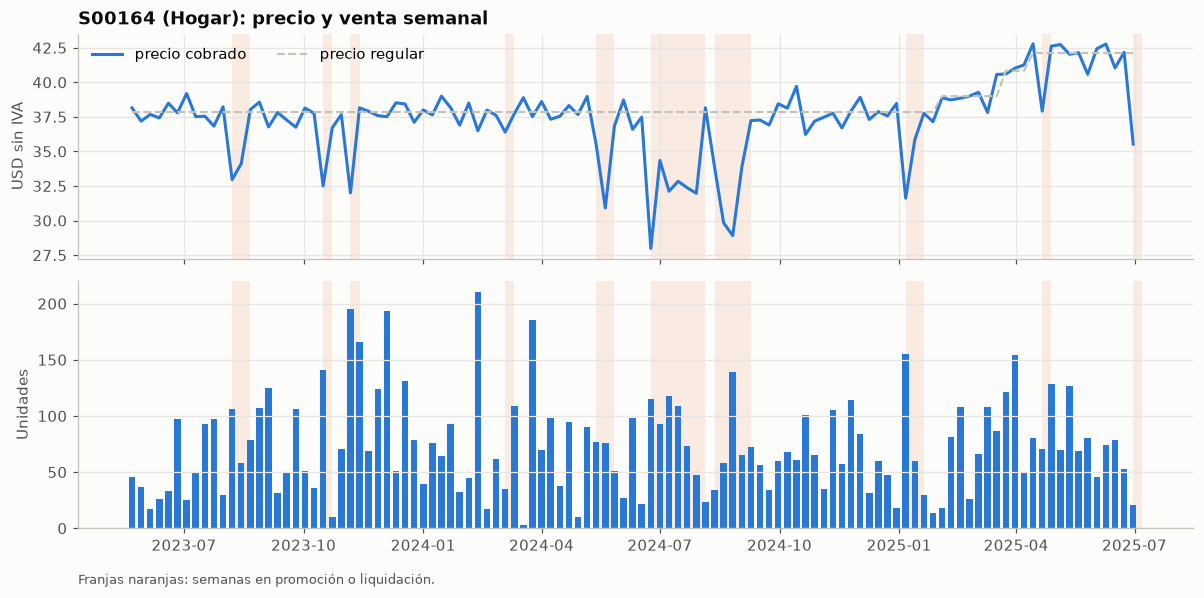

In [3]:
vida = v.groupby('sku').size()
cand = v[v.sku.isin(vida[vida > 100].index)].groupby('sku').agg(u=('unidades', 'mean'), pr=('en_promocion', 'mean'))
s_ej = cand[(cand.u.between(20, 200))].sort_values('pr').index[len(cand[(cand.u.between(20, 200))]) // 2]
g = v[v.sku == s_ej]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True, gridspec_kw={'height_ratios': [1, 1.1]})
a1.plot(g.semana, g.precio, color=AZUL, label='precio cobrado'); a1.plot(g.semana, g.precio_regular, color=GRIS, ls='--', lw=1.4, label='precio regular')
for f in g.semana[g.en_promocion]:
    for ax in (a1, a2):
        ax.axvspan(f, f + pd.Timedelta(days=7), color=NARANJA, alpha=0.12, lw=0)
a1.set_ylabel('USD sin IVA'); a1.legend(loc='upper left', ncol=2); a1.set_title(f'{s_ej} ({g.division.iloc[0].title()}): precio y venta semanal')
a2.bar(g.semana, g.unidades, width=5, color=AZUL); a2.set_ylabel('Unidades'); a2.grid(axis='x', visible=False)
pie(a2, 'Franjas naranjas: semanas en promoción o liquidación.')
plt.tight_layout(); plt.show()

### 3. La temporada

Venta relativa por semana del año (1 = semana promedio del SKU). Navidad y Juguetes se concentran en noviembre–diciembre; Electro tiene picos en Black Friday y Día de la Madre.

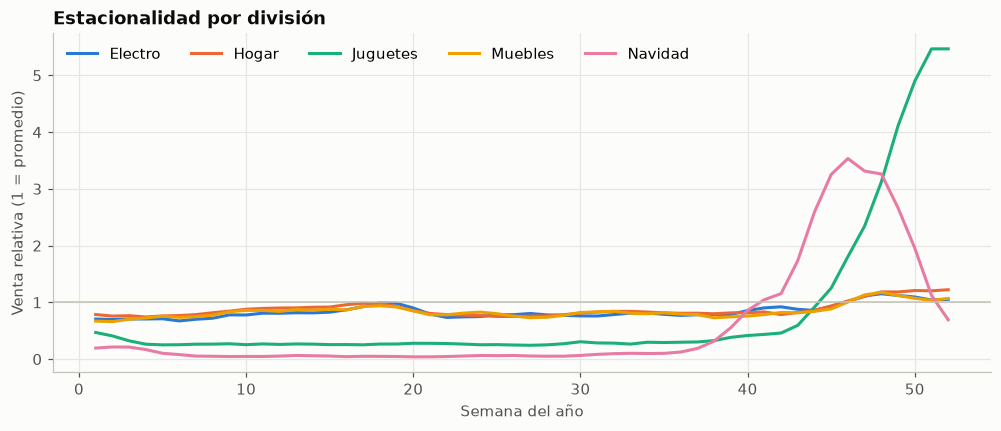

In [4]:
rel = v[v.unidades > 0].assign(rel=lambda x: x.unidades / x.groupby('sku').unidades.transform('mean'))
est = rel.groupby(['division', 'semana_del_año']).rel.median().unstack(0)
est = est.rolling(3, center=True, min_periods=1).mean()
fig, ax = plt.subplots(figsize=(11, 4))
for c, col in zip(est.columns, SERIES):
    ax.plot(est.index, est[c], color=col, label=c.title())
ax.axhline(1, color=GRIS, lw=1); ax.set_xlabel('Semana del año'); ax.set_ylabel('Venta relativa (1 = promedio)')
ax.set_title('Estacionalidad por división'); ax.legend(ncol=5, loc='upper left')
plt.show()

### 4. La trampa de la elasticidad

Elasticidad = cuánto cambian las unidades cuando el precio cambia 1 % (−1 significa que si el precio sube 10 %, las unidades caen ~10 %).

Se mide de dos formas, ambas dentro de cada SKU y descontando la semana:
- **solo precio** ("tal cual"): mezcla el efecto del precio con el de la publicidad de las promociones;
- **precio + control de promoción**: separa el empuje de la publicidad.

Si las dos dan distinto, la medición "tal cual" está contaminada.

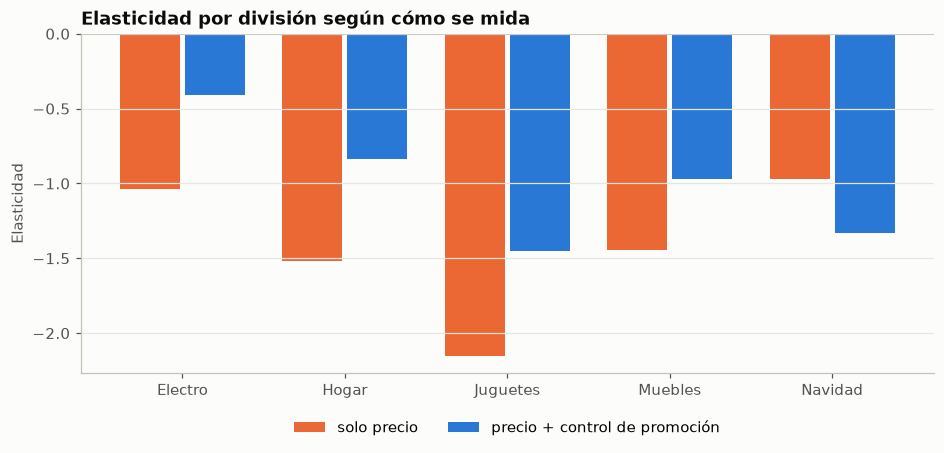

,solo precio,precio + control de promoción,empuje de la promoción (log)
division,,,
ELECTRO,-1.039,-0.411,0.125
HOGAR,-1.520,-0.837,0.147
JUGUETES,-2.156,-1.448,0.176
MUEBLES,-1.446,-0.972,0.106
NAVIDAD,-0.969,-1.334,-0.131


In [5]:
def dos_vias(df, col, it=6):
    """Quita el efecto de cada SKU y de cada semana (efectos fijos)."""
    x = df[col].copy()
    for _ in range(it):
        x = x - x.groupby(df.sku).transform('mean')
        x = x - x.groupby(df.semana).transform('mean')
    return x

x = v[(v.unidades > 0) & (v.semana <= CORTES['validacion'][1])].copy()
x['ly'], x['lx'], x['pr'] = np.log(x.unidades), np.log(x.precio), x.en_promocion.astype(float)
filas = []
for d, g in x.groupby('division'):
    Y, X, P = dos_vias(g, 'ly'), dos_vias(g, 'lx'), dos_vias(g, 'pr')
    solo = float((X * Y).sum() / (X ** 2).sum())
    b = np.linalg.lstsq(np.column_stack([X, P]), Y, rcond=None)[0]
    filas.append({'division': d, 'solo precio': solo, 'precio + control de promoción': b[0], 'empuje de la promoción (log)': b[1]})
E = pd.DataFrame(filas).set_index('division')
if HAY_VERDAD:
    par = pd.read_parquet(DATOS / 'verdad' / 'parametros_sku.parquet')
    E['verdadera (promedio)'] = par.groupby('division').elasticidad.mean()
fig, ax = plt.subplots(figsize=(10, 4))
cols = [c for c in E.columns if c != 'empuje de la promoción (log)']
w = 0.8 / len(cols); xs = np.arange(len(E))
for i, (c, col) in enumerate(zip(cols, [NARANJA, AZUL, AQUA])):
    ax.bar(xs + (i - (len(cols) - 1) / 2) * w, E[c], width=w - 0.03, color=col, label=c)
ax.set_xticks(xs, [d.title() for d in E.index]); ax.axhline(0, color=GRIS, lw=1); ax.grid(axis='x', visible=False)
ax.set_ylabel('Elasticidad'); ax.set_title('Elasticidad por división según cómo se mida'); ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.1))
plt.show()
E.round(3)

### 5. El ciclo de vida: otra trampa

Antes de salir del catálogo, la venta de un SKU cae y muchas veces se liquida (se baja el precio). Si un modelo mira solo precio y venta, concluye que bajar el precio **hace caer** la venta.

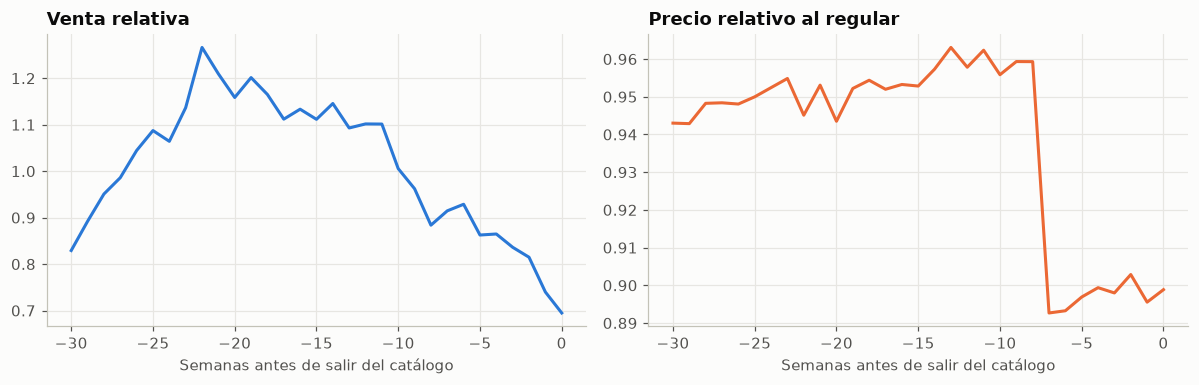

In [6]:
ult = v.groupby('sku').semana.transform('max')
salieron = v[ult < v.semana.max() - pd.Timedelta(weeks=4)].copy()
salieron['antes'] = ((ult[salieron.index] - salieron.semana).dt.days // 7)
salieron['u_rel'] = salieron.unidades / salieron.groupby('sku').unidades.transform('mean')
salieron['p_rel'] = salieron.precio / salieron.groupby('sku').precio_regular.transform('median')
t = salieron[salieron.antes <= 30].groupby('antes')[['u_rel', 'p_rel']].mean()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.plot(-t.index, t.u_rel, color=AZUL); a1.set_title('Venta relativa'); a1.set_xlabel('Semanas antes de salir del catálogo')
a2.plot(-t.index, t.p_rel, color=NARANJA); a2.set_title('Precio relativo al regular'); a2.set_xlabel('Semanas antes de salir del catálogo')
plt.tight_layout(); plt.show()

### 6. ¿Se parece a lo real?

Por división: lo medido en la venta real de Pycca frente a lo medido, con el mismo método, en la sintética.

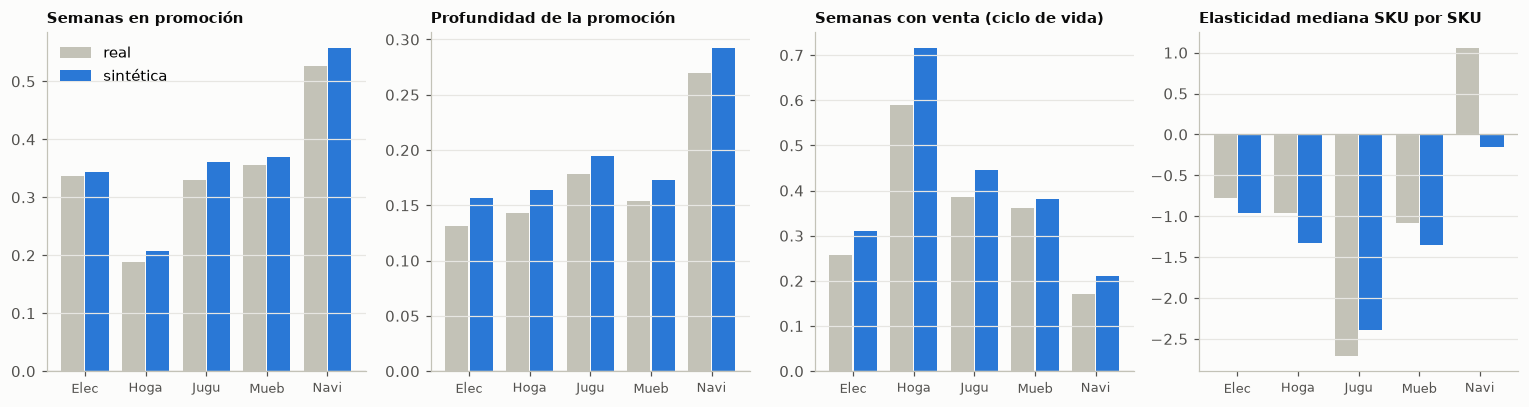

Correlación de la estacionalidad semanal real vs sintética por división: {'ELECTRO': 0.87, 'HOGAR': 0.89, 'JUGUETES': 0.98, 'MUEBLES': 0.82, 'NAVIDAD': 0.97}


In [7]:
val = pd.read_csv(RAIZ / 'validacion.csv').set_index('division')
pares = [('promo_real', 'promo_sint', 'Semanas en promoción'), ('prof_real', 'prof_sint', 'Profundidad de la promoción'),
         ('semanas_con_venta_real', 'semanas_con_venta_sint', 'Semanas con venta (ciclo de vida)'),
         ('elast_sku_mediana_real', 'elast_sku_mediana_sint', 'Elasticidad mediana SKU por SKU')]
fig, axs = plt.subplots(1, 4, figsize=(14, 3.8))
xs = np.arange(len(val))
for ax, (a, b, t) in zip(axs, pares):
    ax.bar(xs - 0.2, val[a], width=0.38, color=GRIS, label='real'); ax.bar(xs + 0.2, val[b], width=0.38, color=AZUL, label='sintética')
    ax.set_xticks(xs, [d[:4].title() for d in val.index], fontsize=8.5); ax.set_title(t, fontsize=10); ax.grid(axis='x', visible=False)
    ax.axhline(0, color=GRIS, lw=0.8)
axs[0].legend(loc='upper left'); plt.tight_layout(); plt.show()
print('Correlación de la estacionalidad semanal real vs sintética por división:', val.corr_estacionalidad.round(2).to_dict())

**Resumen.** La sintética reproduce las promociones, la temporada, el ciclo de vida y el nivel de venta de cada división. La elasticidad mediana medida SKU por SKU se parece a la real, salvo en Navidad: en lo real sale positiva, por el remate de enero. Los **supuestos** (no medibles sin experimentos) son el empuje de la publicidad (+15 %), el efecto del precio de la competencia y los cambios de precio permanentes de 2025.

Siguiente: **02_baseline.ipynb**.